# Dataset Visualization
Visualizing the processed Wine Quality dataset.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load the processed data we generated yesterday
train_df = pd.read_csv("../data/processed/train.csv")
print(f"Train set shape: {train_df.shape}")
train_df.head()

Train set shape: (1087, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,is_good
0,0.951756,-0.262806,-0.183477,0.109359,0.306271,-0.298727,-0.467422,1.736363,-0.187013,-0.569382,-0.391982,0
1,0.951756,-1.454793,1.367780,-0.464909,-0.097935,2.425246,0.765124,-1.183761,-2.120585,-0.160855,1.270366,1
2,-0.298672,0.008100,0.281900,-0.105991,-0.161756,0.734504,2.819368,-0.098688,-0.058108,-0.335938,-0.853746,0
3,0.610730,-1.075525,1.626322,0.181143,-0.183030,-0.674447,-0.526115,0.459806,-1.218251,-0.686104,1.455072,0
4,-0.753373,-0.804619,1.109237,-0.034208,0.199901,1.579875,1.087934,-0.284852,0.521964,0.656199,0.900956,0


## 1. Class Balance
How many wines are classified as 'good' (quality >= 7) vs 'not good'?

/tmp/ipykernel_2900/3983824194.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train_df, x="is_good", palette="Set2")


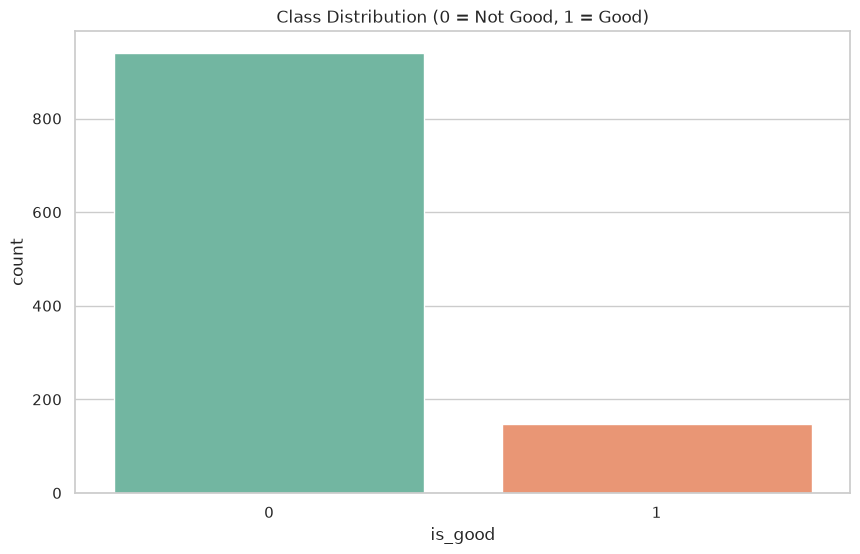

is_good
0    0.864765
1    0.135235
Name: proportion, dtype: float64


In [2]:
sns.countplot(data=train_df, x="is_good", palette="Set2")
plt.title("Class Distribution (0 = Not Good, 1 = Good)")
plt.show()

print(train_df["is_good"].value_counts(normalize=True))

## 2. Feature Distributions
Since the data is scaled, the mean is roughly 0 and the standard deviation is 1.

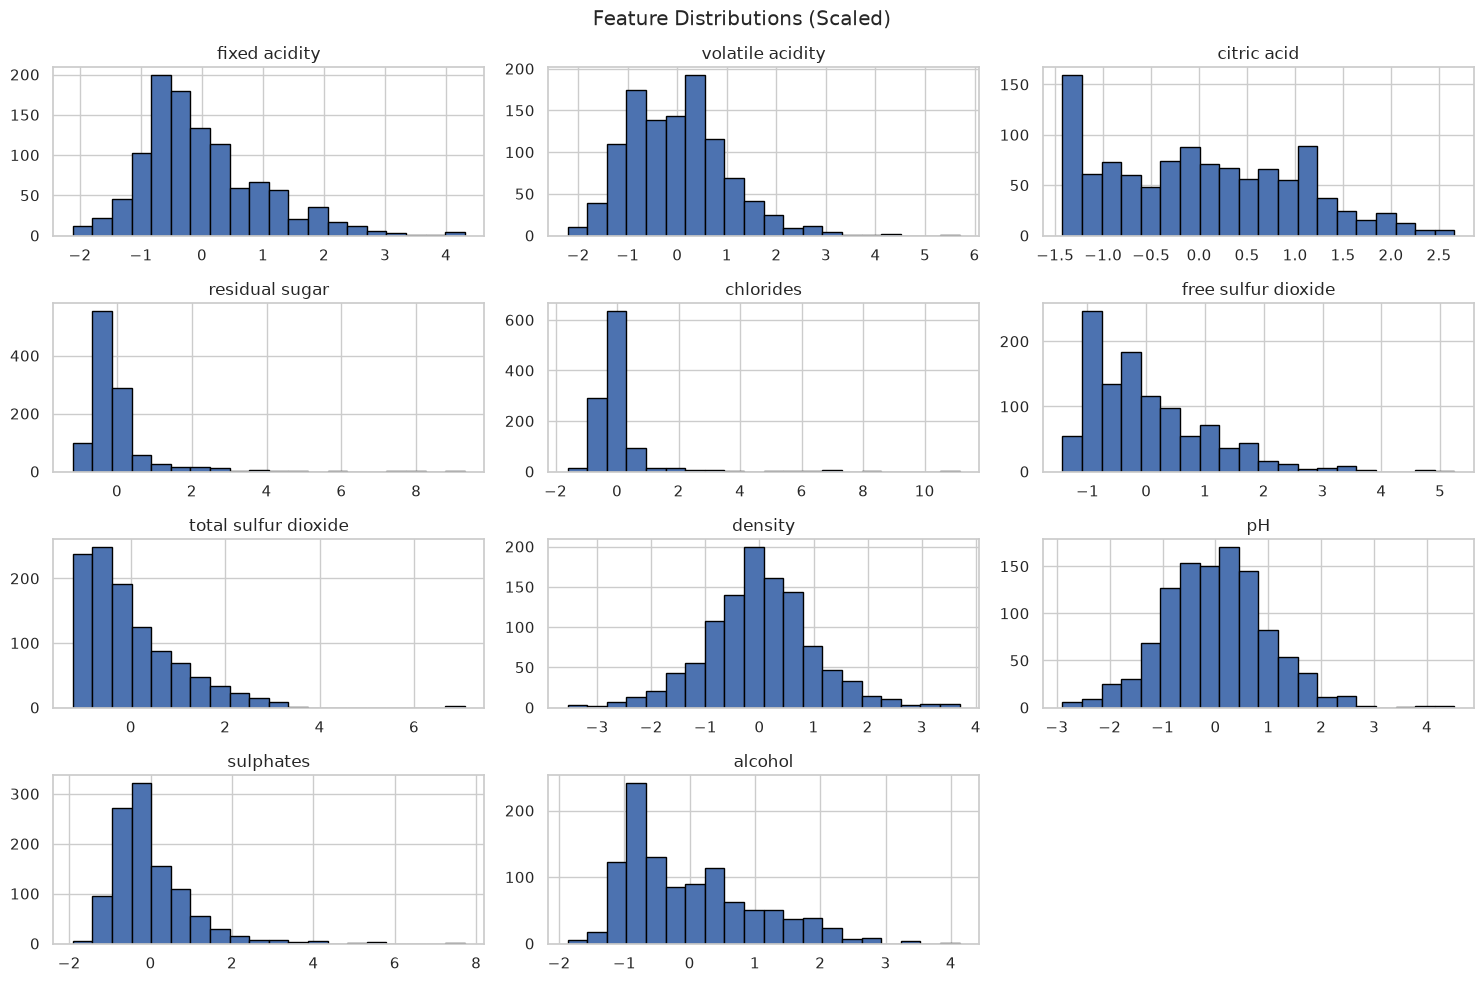

In [3]:
features = [c for c in train_df.columns if c != "is_good"]
train_df[features].hist(bins=20, figsize=(15, 10), edgecolor="black")
plt.suptitle("Feature Distributions (Scaled)")
plt.tight_layout()
plt.show()

## 3. PCA Visualization
Reduce the 11 features down to 2 dimensions to see if 'good' and 'not good' wines form distinct clusters.

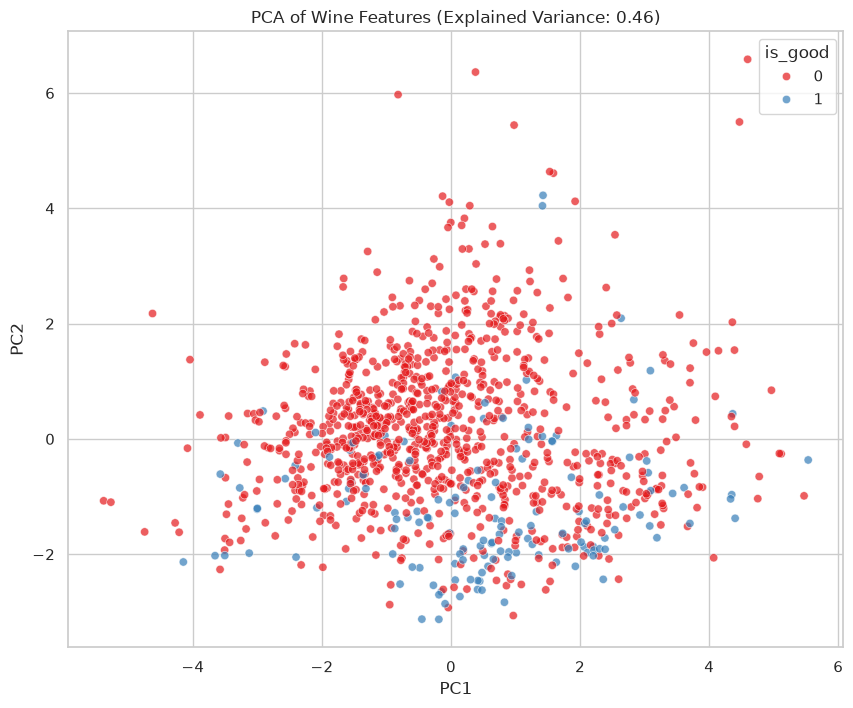

Explained variance ratio: [0.28028831 0.17520688]


In [4]:
X = train_df[features]
y = train_df["is_good"]

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

# Create a DataFrame for plotting
pca_df = pd.DataFrame(data=X_pca, columns=["PC1", "PC2"])
pca_df["is_good"] = y.values

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x="PC1", y="PC2", 
    hue="is_good", 
    palette="Set1", 
    data=pca_df, 
    alpha=0.7
)
plt.title(f"PCA of Wine Features (Explained Variance: {pca.explained_variance_ratio_.sum():.2f})")
plt.show()

print(f"Explained variance ratio: {pca.explained_variance_ratio_}")

## Findings
- Write what you observe here. (e.g., Do the classes overlap heavily in PCA? Are there outliers?)